# Lokoja evidence pair and independent-label review queue

The case adds a riverine confluence stress-test to the Lagos engineering ROI; it does not validate urban pluvial flood-warning skill. Selection: closest full-footprint acquisition to 15 October 2022 within October, and a prior-year October reference constrained to the same relative orbit/pass. Pair grids and orbits are checked.

Regional NASA/UNOSAT reporting motivates the review window. It does not supply 10m/100m truth for each chip. A prior-year image is not a verified negative. Model-output changes are diagnostics only.

The review queue starts with blank labels and one shared group ID. Human review should use raw paired imagery and independent evidence, without model overlays. Record evidence timing, reviewer and uncertainty. Chip-level scene labels are not pixel masks and cannot automatically label every 100m cell. 72-hour onset targets need separate timing evidence. All chips/dates from this case stay together in any eventual data split.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))


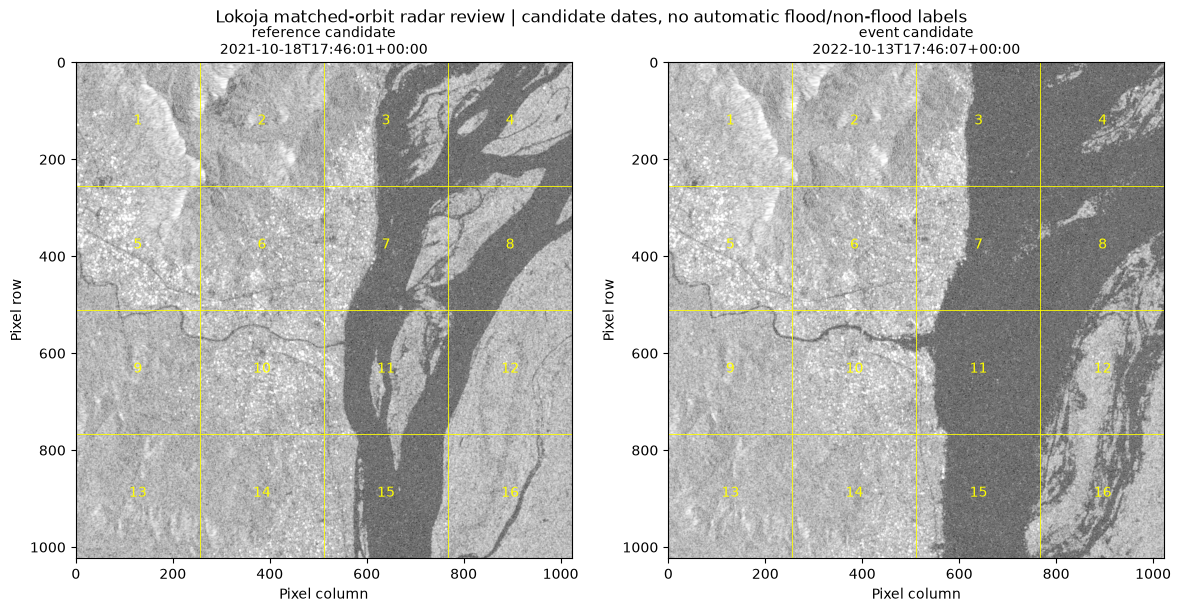

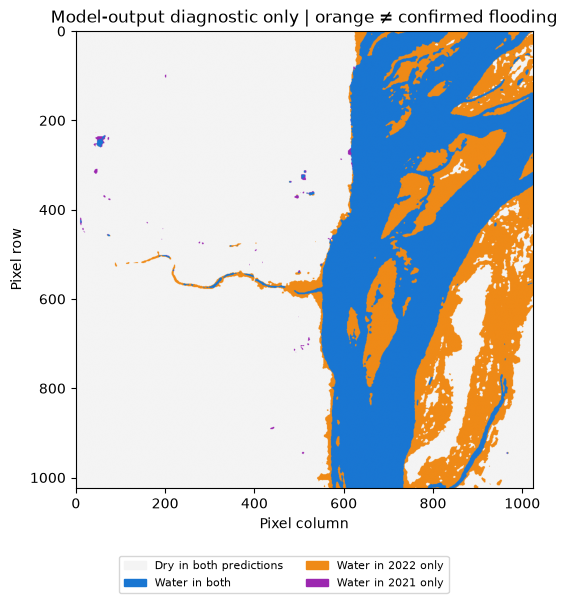

{
  "scene_dates": {
    "reference_candidate": "2021-10-18T17:46:01+00:00",
    "event_candidate": "2022-10-13T17:46:07+00:00"
  },
  "pair_orbit": 30,
  "pair_pass": "ASCENDING",
  "review_chips": 16,
  "reviewed_scene_labels": 0,
  "pixel_categories": {
    "0": 650409,
    "1": 243852,
    "2": 153364,
    "3": 951,
    "255": 0
  },
  "meaning": "Model-derived change candidates only; not independently reviewed flood labels, training targets or accuracy scores"
}


In [2]:
import csv
import json
import shutil
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap,BoundaryNorm
from matplotlib.patches import Patch
from floodrisk.deploy.tiled import predict_scene
from floodrisk.features.evidence import review_queue,eligible_scene_labels

source=PROJECT / "data/scenes/lokoja_2022_review"
out=PROJECT / "reports/evidence/lokoja_2022_review"
out.mkdir(parents=True,exist_ok=True)
shutil.copy2(source/"pair.json",out/"pair.json")
pair=json.loads((out/"pair.json").read_text())
queue=review_queue(pair)
# Preserve a queue after a person starts reviewing it.
queue_path=out/"review_queue.csv"
if not queue_path.exists():
    with queue_path.open("w") as f:
        writer=csv.DictWriter(f,fieldnames=list(queue[0]));writer.writeheader();writer.writerows(queue)
with queue_path.open() as f:reviewed=list(csv.DictReader(f))
assert len(reviewed)==len(queue)
accepted=eligible_scene_labels(reviewed)
export=PROJECT / "reports/m1-s1-kaggle-365653491/onnx_fp32"
radar={};masks={};grids={}
for role in ["reference_candidate","event_candidate"]:
    image=source/role/"sentinel1_vv_vh_db.tif"
    destination=PROJECT / f"data/predictions/lokoja_2022_review/{role}"
    if not destination.exists():
        predict_scene(image,export/"m1_s1_fp32.onnx",export/"inference_config.json",destination,halo=64)
    shutil.copy2(destination/"prediction.json",out/f"{role}_prediction.json")
    with rasterio.open(image) as src:
        radar[role]=src.read(2,masked=True);grids[role]=src.crs,src.transform,src.shape
    with rasterio.open(destination/"water_mask.tif") as src:masks[role]=src.read(1)
assert grids["reference_candidate"]==grids["event_candidate"]
from datetime import datetime,timezone
labels={role:datetime.fromtimestamp(pair["acquisitions"][role]["source"]["system:time_start"]/1000,timezone.utc).isoformat() for role in radar}
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,role in zip(axes,["reference_candidate","event_candidate"]):
    ax.imshow(radar[role],cmap="gray",vmin=-42,vmax=-5)
    ax.set_title(role.replace("_"," ")+"\n"+labels[role],fontsize=10)
    for line in [256,512,768]:ax.axvline(line-0.5,color="yellow",linewidth=0.6);ax.axhline(line-0.5,color="yellow",linewidth=0.6)
    for i,row in enumerate(queue):ax.text(int(row["col_off"])+128,int(row["row_off"])+128,str(i+1),ha="center",color="yellow")
    ax.set_xlabel("Pixel column");ax.set_ylabel("Pixel row")
fig.suptitle("Lokoja matched-orbit radar review | candidate dates, no automatic flood/non-flood labels")
fig.tight_layout();fig.savefig(out/"radar_review_pair.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
a=masks["reference_candidate"];b=masks["event_candidate"]
valid=(a!=255)&(b!=255)
change=np.full(a.shape,255,dtype="uint8")
change[valid]=0;change[valid&(a==1)&(b==1)]=1
change[valid&(a==0)&(b==1)]=2;change[valid&(a==1)&(b==0)]=3
fig,ax=plt.subplots(figsize=(7,6))
colors=["#f4f4f4","#1976d2","#ef8a17","#9c27b0"]
cmap=ListedColormap(colors);cmap.set_bad("#bcbcbc")
ax.imshow(np.ma.masked_equal(change,255),cmap=cmap,norm=BoundaryNorm([-0.5,0.5,1.5,2.5,3.5],4))
ax.set_title("Model-output diagnostic only | orange ≠ confirmed flooding")
ax.set_xlabel("Pixel column");ax.set_ylabel("Pixel row")
fig.legend(handles=[Patch(color=c,label=label) for c,label in zip(colors,["Dry in both predictions","Water in both","Water in 2022 only","Water in 2021 only"])],loc="lower center",ncol=2,fontsize=8)
fig.tight_layout(rect=[0,0.08,1,1]);fig.savefig(out/"model_change_candidates.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
summary=dict(scene_dates=labels,pair_orbit=pair["acquisitions"]["event_candidate"]["source"]["relativeOrbitNumber_start"],
    pair_pass=pair["acquisitions"]["event_candidate"]["source"]["orbitProperties_pass"],
    review_chips=len(queue),reviewed_scene_labels=len(accepted),
    pixel_categories={str(k):int((change==k).sum()) for k in [0,1,2,3,255]},
    meaning="Model-derived change candidates only; not independently reviewed flood labels, training targets or accuracy scores")
(out/"summary.json").write_text(json.dumps(summary,indent=2)+"\n")
print(json.dumps(summary,indent=2))
